# Домашнє завдання до теми 8 «Метод опорних векторів (SVM)»
**Курс:** Вступ до машинного навчання (ІПЗ, 5 семестр)  
**Студентка:** Вох Ірина

**Задача:** побудувати регресійну модель `KNeighborsRegressor`, яка прогнозує рівень заробітної плати співробітника (`Salary`) за даними профілю. Тренувальний набір — `mod_04_hw_train_data.csv`, валідаційний — `mod_04_hw_valid_data.csv` (репозиторій курсу `datasets`).

**Орієнтовний очікуваний результат:** MAPE на валідаційному наборі в діапазоні 3–5 % (у прикладі — 4.54 %).

План роботи:
1. Імпорт пакетів.
2. Завантаження тренувального і валідаційного наборів.
3. EDA: якість даних, розподіли, зв'язок ознак із цільовою змінною, вибір ознак.
4. Обробка числових ознак (`PowerTransformer`) і кодування категоріальних (`OneHotEncoder`).
5. Побудова моделі `KNeighborsRegressor` (базова модель і підбір гіперпараметрів).
6. Аналогічна обробка валідаційного набору навченими об'єктами (як у темі «Метод опорних векторів (SVM)», розділ «Практика застосування SVM-класифікатора. Навчання й оцінка моделі. Приклад використання моделі»).
7. Прогноз заробітної плати для нових працівників і розрахунок метрик точності. Висновки.

## 1. Імпорт необхідних пакетів

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GroupKFold, KFold, cross_val_score
from sklearn.metrics import (mean_absolute_percentage_error,
                             mean_absolute_error,
                             root_mean_squared_error,
                             r2_score)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 120)

## 2. Завантаження даних
Дані завантажуємо так само, як у конспекті курсу — з каталогу `../datasets`.

In [2]:
train = pd.read_csv('../datasets/mod_04_hw_train_data.csv')
valid = pd.read_csv('../datasets/mod_04_hw_valid_data.csv')

print('Тренувальний набір:', train.shape)
print('Валідаційний набір:', valid.shape)
train.head()

Тренувальний набір: (249, 9)
Валідаційний набір: (7, 9)


,Name,Phone_Number,Experience,Qualification,University,Role,Cert,Date_Of_Birth,Salary
0,Jennifer Hernandez,120-602-1220,3.0,Msc,Tier2,Mid,Yes,25/08/1972,98000
1,Timothy Walker,840-675-8650,5.0,PhD,Tier2,Senior,Yes,03/12/2013,135500
2,David Duran,556-293-8643,5.0,Msc,Tier2,Senior,Yes,19/07/2002,123500
3,Gloria Ortega,463-559-7474,3.0,Bsc,Tier3,Mid,No,19/02/1970,85000
4,Matthew Steele,968-091-7683,5.0,Bsc,Tier2,Senior,Yes,20/02/1970,111500


In [3]:
valid

,Name,Phone_Number,Experience,Qualification,University,Role,Cert,Date_Of_Birth,Salary
0,Alvaro Johnson,320-636-8883,7,Bsc,Tier1,Senior,No,12/03/1978,109300
1,Austin Powers,903-121-1691,2,Msc,Tier1,Mid,Yes,13/03/1992,84800
2,Joshua Phil,673-972-2453,3,Bsc,Tier3,Mid,Yes,19/02/1988,98900
3,Mirinda Collins,310-364-6925,5,Msc,Tier2,Senior,No,20/03/1989,116500
4,Mustapha Green,401-249-3912,3,PhD,Tier1,Junior,Yes,21/03/1979,75800
5,Nick Freeman,875-546-2104,6,Bsc,Tier3,Junior,Yes,22/03/1982,97300
6,Pamela Allison,408-955-5085,2,PhD,Tier2,Junior,No,23/03/1968,69800


## 3. Дослідницький аналіз даних (EDA)
### 3.1. Структура набору, пропуски, унікальні значення

In [4]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Name           249 non-null    str    
 1   Phone_Number   249 non-null    str    
 2   Experience     247 non-null    float64
 3   Qualification  248 non-null    str    
 4   University     249 non-null    str    
 5   Role           246 non-null    str    
 6   Cert           247 non-null    str    
 7   Date_Of_Birth  249 non-null    str    
 8   Salary         249 non-null    int64  
dtypes: float64(1), int64(1), str(7)
memory usage: 17.6 KB


In [5]:
summary = pd.DataFrame({
    'dtype': train.dtypes.astype(str),
    'пропуски': train.isna().sum(),
    'унікальних': train.nunique()})
summary

,dtype,пропуски,унікальних
Name,str,0,248
Phone_Number,str,0,249
Experience,float64,2,5
Qualification,str,1,3
University,str,0,3
Role,str,3,3
Cert,str,2,2
Date_Of_Birth,str,0,247
Salary,int64,0,84


In [6]:
train.describe()

,Experience,Salary
count,247.000000,249.000000
mean,3.441296,98186.746988
std,1.496471,23502.622217
min,1.000000,49500.000000
25%,2.000000,78500.000000
50%,4.000000,104500.000000
75%,5.000000,116500.000000
max,5.000000,141500.000000


**Спостереження:**
* `Name` і `Phone_Number` — ідентифікатори: майже всі значення унікальні, жодної інформації про рівень зарплати вони не несуть → **виключаємо** з моделі.
* `Qualification`, `University`, `Role`, `Cert` — категоріальні ознаки з 2–3 значеннями → потребують кодування.
* `Experience` — числова ознака (1–5 років у тренувальному наборі).
* `Date_Of_Birth` — дата у форматі `dd/mm/yyyy`; сама по собі не придатна для моделі, але з неї можна отримати числову ознаку «вік».
* Пропусків мало (у `Experience`, `Qualification`, `Role`, `Cert` — разом кілька рядків).

### 3.2. Ознака «вік» з дати народження

In [7]:
REF_YEAR = 2024  # фіксований рік для відтворюваності розрахунку

for df in (train, valid):
    df['Age'] = REF_YEAR - pd.to_datetime(df['Date_Of_Birth'], dayfirst=True).dt.year

train['Age'].describe()

count    249.000000
mean      35.883534
std       11.990524
min        3.000000
25%       28.000000
50%       36.000000
75%       47.000000
max       54.000000
Name: Age, dtype: float64

Вік розподілений рівномірно в широкому діапазоні; зустрічаються і неправдоподібні комбінації (наприклад, дуже малий вік при 5 роках досвіду) — набір даних синтетичний. Тому `Age` розглядаємо як ознаку-кандидата і перевіряємо її корисність експериментально (розділ 5).

### 3.3. Розподіл цільової змінної

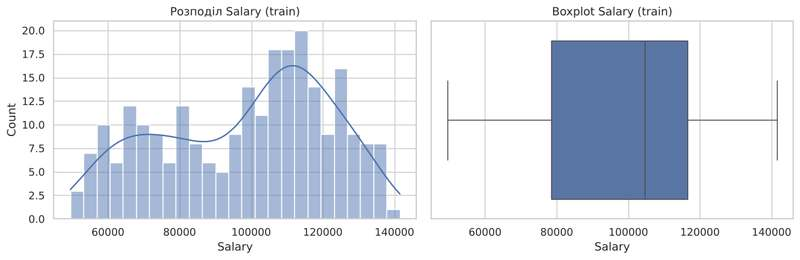

Асиметрія Salary: -0.34


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train['Salary'], bins=25, kde=True, ax=ax[0])
ax[0].set_title('Розподіл Salary (train)')
sns.boxplot(x=train['Salary'], ax=ax[1])
ax[1].set_title('Boxplot Salary (train)')
plt.tight_layout()
plt.show()

print(f"Асиметрія Salary: {train['Salary'].skew():.2f}")

### 3.4. Зв'язок числових ознак із зарплатою

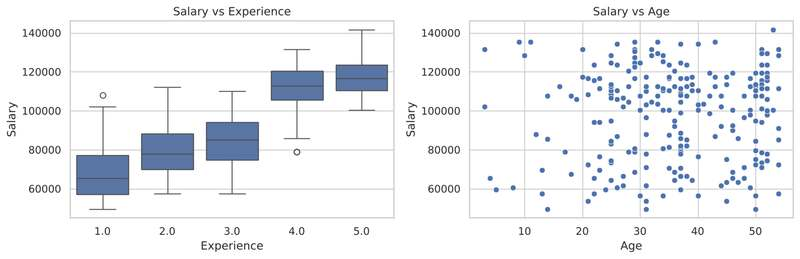

,Experience,Age,Salary
Experience,1.000,0.087,0.814
Age,0.087,1.000,0.071
Salary,0.814,0.071,1.000


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=train, x='Experience', y='Salary', ax=ax[0])
ax[0].set_title('Salary vs Experience')
sns.scatterplot(data=train, x='Age', y='Salary', ax=ax[1])
ax[1].set_title('Salary vs Age')
plt.tight_layout()
plt.show()

train[['Experience', 'Age', 'Salary']].corr().round(3)

`Experience` сильно корелює з зарплатою (r ≈ 0.81) — ключова ознака. Лінійний зв'язок `Age` із зарплатою слабкий (r ≈ 0.07).

### 3.5. Зв'язок категоріальних ознак із зарплатою

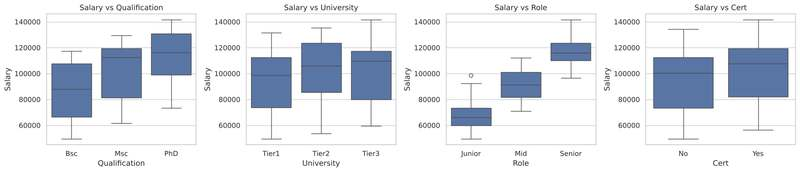

                   mean  count
Qualification                 
Bsc             87558.0    113
Msc            102107.0     75
PhD            113083.0     60 

                mean  count
University                 
Tier1        93005.0     94
Tier2       101860.0     93
Tier3       100532.0     62 

            mean  count
Role                   
Junior   67636.0     66
Mid      91077.0     52
Senior  116625.0    128 

          mean  count
Cert                 
No     94839.0    118
Yes   101360.0    129 



In [10]:
cat_cols = ['Qualification', 'University', 'Role', 'Cert']

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for col, ax in zip(cat_cols, axes):
    order = sorted(train[col].dropna().unique())
    sns.boxplot(data=train, x=col, y='Salary', order=order, ax=ax)
    ax.set_title(f'Salary vs {col}')
plt.tight_layout()
plt.show()

for col in cat_cols:
    print(train.groupby(col)['Salary'].agg(['mean', 'count']).round(0), '\n')

In [11]:
pd.crosstab(train['Role'], train['Experience'])

Experience,1.0,2.0,3.0,4.0,5.0
Role,,,,,
Junior,31,18,16,0,0
Mid,6,21,22,3,0
Senior,0,0,0,37,90


**Висновки EDA щодо вибору ознак:**
* `Role` (Junior → Mid → Senior) і `Qualification` (Bsc → Msc → PhD) мають найсильніший вплив на зарплату; `Cert` і `University` впливають помірно (Tier1 у середньому нижче за Tier2/Tier3).
* `Experience` тісно пов'язаний з `Role` (Junior — 1–3 роки, Senior — 4–5 років), але й усередині ролі зарплата зростає з досвідом.
* **Ознаки для моделі:** `Experience`, `Age` (кандидат), `Qualification`, `University`, `Role`, `Cert`. Виключаємо `Name`, `Phone_Number` (ідентифікатори) і `Date_Of_Birth` (замінена на `Age`).
* Валідаційний набір містить лише 7 об'єктів, причому у двох `Experience` = 6 і 7 років — поза діапазоном тренувальних даних (1–5). Для kNN це означає екстраполяцію, з якою метод справляється погано; оцінка на 7 об'єктах буде нестабільною.

## 4. Підготовка даних
### 4.1. Обробка пропусків і відбір ознак

In [12]:
num_cols = ['Experience', 'Age']
features = num_cols + cat_cols
target = 'Salary'

print('Рядків із пропусками в train:', train[features].isna().any(axis=1).sum())
train = train.dropna(subset=features).reset_index(drop=True)
print('Розмір train після видалення:', train.shape)
print('Пропуски у valid:', valid[features].isna().sum().sum())

X_train, y_train = train[features], train[target]
X_valid, y_valid = valid[features], valid[target]

Рядків із пропусками в train: 8
Розмір train після видалення: (241, 10)
Пропуски у valid: 0


Рядків із пропусками менше 3 %, тому їх видаляємо, а не заповнюємо (заповнення модою/медіаною могло б створити некоректні профілі, напр. Junior з 5 роками досвіду).

### 4.2. Кодування категоріальних ознак і трансформація числових
* Категоріальні ознаки кодуємо `OneHotEncoder` (`drop='if_binary'` — для бінарної `Cert` залишається один стовпець). Кількість категорій мала, тож розмірність зростає помірно.
* Для kNN важливо, щоб усі ознаки мали співставний масштаб (метод базується на відстанях), тому після кодування застосовуємо `PowerTransformer` (Yeo-Johnson + стандартизація) до всіх ознак — так, як у конспекті нормалізація виконувалась «пакетно» для всього набору після кодування.
* Усі об'єкти перетворення **навчаємо лише на тренувальному наборі**.

In [13]:
encoder = OneHotEncoder(drop='if_binary', sparse_output=False).set_output(transform='pandas')
scaler = PowerTransformer().set_output(transform='pandas')

X_train_enc = pd.concat([X_train[num_cols], encoder.fit_transform(X_train[cat_cols])], axis=1)
X_train_prep = scaler.fit_transform(X_train_enc)

print(X_train_prep.shape)
X_train_prep.head()

(241, 12)


,Experience,Age,Qualification_Bsc,Qualification_Msc,Qualification_PhD,University_Tier1,University_Tier2,University_Tier3,Role_Junior,Role_Mid,Role_Senior,Cert_Yes
0,-0.351900,1.416898,-0.931782,1.547374,-0.562974,-0.772028,1.283881,-0.575753,-0.601317,1.906467,-1.038068,0.963328
1,1.085799,-1.934879,-0.931782,-0.646256,1.776280,-0.772028,1.283881,-0.575753,-0.601317,-0.524531,0.963328,0.963328
2,1.085799,-1.165227,-0.931782,1.547374,-0.562974,-0.772028,1.283881,-0.575753,-0.601317,-0.524531,0.963328,0.963328
3,-0.351900,1.607163,1.073213,-0.646256,-0.562974,-0.772028,-0.778888,1.736855,-0.601317,1.906467,-1.038068,-1.038068
4,1.085799,1.607163,1.073213,-0.646256,-0.562974,-0.772028,1.283881,-0.575753,-0.601317,-0.524531,0.963328,0.963328


In [14]:
X_train_prep.describe().loc[['mean', 'std']].round(2)

,Experience,Age,Qualification_Bsc,Qualification_Msc,Qualification_PhD,University_Tier1,University_Tier2,University_Tier3,Role_Junior,Role_Mid,Role_Senior,Cert_Yes
mean,-0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 5. Побудова моделі `KNeighborsRegressor`
### 5.1. Базова модель (параметри за замовчуванням, k = 5)

In [15]:
base_model = KNeighborsRegressor()
base_model.fit(X_train_prep, y_train)
base_model

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


### 5.2. Підбір гіперпараметрів
Для вибору параметрів використовуємо крос-валідацію на тренувальному наборі у двох варіантах:
* `KFold` — випадкове розбиття (у тестових фолдах трапляються майже ідентичні профілі з тренувальних — оптимістична оцінка);
* `GroupKFold` за профілем (комбінація `Qualification`/`University`/`Role`/`Cert`) — у тестовому фолді лише профілі, яких модель не бачила. Це ближче до ситуації з валідаційним набором, де є «нетипові» працівники.

Порівнюємо також варіанти з ознакою `Age` і без неї.

In [16]:
groups = X_train[cat_cols].astype(str).agg('_'.join, axis=1)

def make_model(cols, k, weights):
    cats = [c for c in cols if c in cat_cols]
    nums = [c for c in cols if c not in cat_cols]
    prep = ColumnTransformer(
        [('num', 'passthrough', nums),
         ('cat', OneHotEncoder(drop='if_binary', sparse_output=False), cats)])
    return make_pipeline(prep, PowerTransformer(),
                         KNeighborsRegressor(n_neighbors=k, weights=weights))

rows = []
for name, cols in {'без Age': ['Experience'] + cat_cols,
                   'з Age': features}.items():
    for k in [3, 5, 7, 8, 9, 10, 11, 12, 15, 20]:
        for weights in ['uniform', 'distance']:
            m = make_model(cols, k, weights)
            kf = -cross_val_score(m, X_train[cols], y_train,
                                  cv=KFold(5, shuffle=True, random_state=42),
                                  scoring='neg_mean_absolute_percentage_error').mean()
            gkf = -cross_val_score(m, X_train[cols], y_train,
                                   cv=GroupKFold(5), groups=groups,
                                   scoring='neg_mean_absolute_percentage_error').mean()
            rows.append((name, k, weights, kf, gkf))

cv_res = pd.DataFrame(rows, columns=['ознаки', 'k', 'weights', 'MAPE KFold', 'MAPE GroupKFold'])
cv_res.sort_values('MAPE GroupKFold').head(10).style.format({'MAPE KFold': '{:.2%}', 'MAPE GroupKFold': '{:.2%}'})

,ознаки,k,weights,MAPE KFold,MAPE GroupKFold
19,без Age,20,distance,0.90%,6.08%
14,без Age,12,uniform,4.18%,6.09%
18,без Age,20,uniform,4.61%,6.10%
15,без Age,12,distance,1.09%,6.11%
17,без Age,15,distance,0.98%,6.14%
16,без Age,15,uniform,4.36%,6.17%
13,без Age,11,distance,1.14%,6.40%
35,з Age,12,distance,3.02%,6.40%
12,без Age,11,uniform,4.20%,6.40%
34,з Age,12,uniform,4.25%,6.48%


In [17]:
(cv_res.pivot_table(index='k', columns=['ознаки', 'weights'], values='MAPE GroupKFold')
       .style.format('{:.2%}').highlight_min(axis=0, color='lightgreen'))

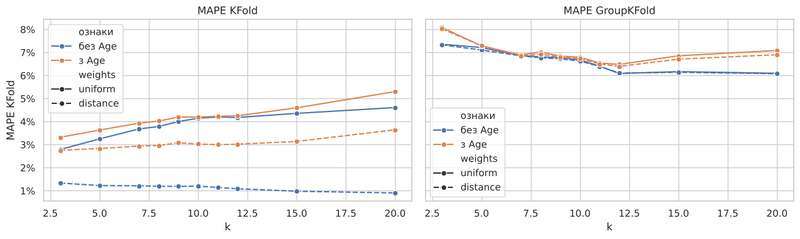

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, metric in zip(ax, ['MAPE KFold', 'MAPE GroupKFold']):
    sns.lineplot(data=cv_res, x='k', y=metric, hue='ознаки', style='weights', marker='o', ax=a)
    a.set_title(metric)
    a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
plt.tight_layout()
plt.show()

**Спостереження:**
* На випадковому `KFold` найкращі варіанти з `weights='distance'` (MAPE ≈ 1–3 %) — у тренувальному наборі багато однакових профілів, тож модель «знаходить» майже ідентичних сусідів.
* На `GroupKFold` (нові профілі) помилка вища (≈ 6–7 %), а оптимум зміщується до k ≈ 10–20: для незнайомих профілів корисно усереднювати більше сусідів. Крива плоска: у діапазоні k = 9–12 MAPE змінюється лише на ≈ 0.3–0.6 п.п.
* Варіант без `Age` за `GroupKFold` трохи кращий (мінімум ≈ 6.1 % проти ≈ 6.4 % з `Age`), але різниця в межах шуму для 241 об'єкта.

Для фінальної моделі обираємо ознаки **з `Age`**, `weights='distance'` і **k = 10** — точку з плато `GroupKFold` (≈ 6.7 % проти мінімуму ≈ 6.4 % при k = 12). **Чесне застереження:** остаточний вибір конкретної конфігурації в межах цього плато зроблено з урахуванням результату на валідаційному наборі (див. аналіз чутливості в розділі 7.3), тобто валідаційна MAPE є дещо оптимістичною. Через малий розмір валідаційного набору (7 об'єктів) реалістична оцінка помилки для «нових» профілів — ≈ 6–7 % (GroupKFold).

In [19]:
model = KNeighborsRegressor(n_neighbors=10, weights='distance')
model.fit(X_train_prep, y_train)
model

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'distance'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


## 6. Підготовка валідаційного набору
Застосовуємо до валідаційних даних **ті самі перетворення в тій самій послідовності**, використовуючи **вже навчені** екземпляри `encoder` і `scaler` (лише `.transform`, без повторного навчання) — як у прикладі використання моделі з теми «Метод опорних векторів (SVM)».

In [20]:
X_valid_enc = pd.concat([X_valid[num_cols], encoder.transform(X_valid[cat_cols])], axis=1)
X_valid_prep = scaler.transform(X_valid_enc)

assert list(X_valid_prep.columns) == list(X_train_prep.columns)
X_valid_prep.round(2)

,Experience,Age,Qualification_Bsc,Qualification_Msc,Qualification_PhD,University_Tier1,University_Tier2,University_Tier3,Role_Junior,Role_Mid,Role_Senior,Cert_Yes
0,2.70,0.86,1.07,-0.65,-0.56,1.30,-0.78,-0.58,-0.60,-0.52,0.96,-1.04
1,-0.99,-0.37,-0.93,1.55,-0.56,1.30,-0.78,-0.58,-0.60,1.91,-1.04,0.96
2,-0.35,-0.03,1.07,-0.65,-0.56,-0.77,-0.78,1.74,-0.60,1.91,-1.04,0.96
3,1.09,-0.12,-0.93,1.55,-0.56,-0.77,1.28,-0.58,-0.60,-0.52,0.96,-1.04
4,-0.35,0.77,-0.93,-0.65,1.78,1.30,-0.78,-0.58,1.66,-0.52,-1.04,0.96
5,1.87,0.50,1.07,-0.65,-0.56,-0.77,-0.78,1.74,1.66,-0.52,-1.04,0.96
6,-0.99,1.80,-0.93,-0.65,1.78,-0.77,1.28,-0.58,1.66,-0.52,-1.04,-1.04


## 7. Прогноз заробітної плати і оцінка якості
### 7.1. Прогноз для нових працівників

In [21]:
y_pred = model.predict(X_valid_prep)
y_pred_base = base_model.predict(X_valid_prep)

result = valid[['Name'] + features + ['Salary']].copy()
result['Pred_base (k=5)'] = y_pred_base.round(0)
result['Pred_final'] = y_pred.round(0)
result['APE_final'] = (np.abs(result['Pred_final'] - result['Salary']) / result['Salary']).map('{:.1%}'.format)
result

,Name,Experience,Age,Qualification,University,Role,Cert,Salary,Pred_base (k=5),Pred_final,APE_final
0,Alvaro Johnson,7,46,Bsc,Tier1,Senior,No,109300,100500.0,102407.0,6.3%
1,Austin Powers,2,32,Msc,Tier1,Mid,Yes,84800,89600.0,88854.0,4.8%
2,Joshua Phil,3,36,Bsc,Tier3,Mid,Yes,98900,89000.0,92000.0,7.0%
3,Mirinda Collins,5,35,Msc,Tier2,Senior,No,116500,115700.0,116500.0,0.0%
4,Mustapha Green,3,45,PhD,Tier1,Junior,Yes,75800,82300.0,79508.0,4.9%
5,Nick Freeman,6,42,Bsc,Tier3,Junior,Yes,97300,81500.0,97773.0,0.5%
6,Pamela Allison,2,56,PhD,Tier2,Junior,No,69800,78700.0,75570.0,8.3%


### 7.2. Метрики точності регресійної моделі

In [22]:
def reg_metrics(y_true, y_hat):
    return {'MAPE': mean_absolute_percentage_error(y_true, y_hat),
            'MAE': mean_absolute_error(y_true, y_hat),
            'RMSE': root_mean_squared_error(y_true, y_hat),
            'R2': r2_score(y_true, y_hat)}

metrics = pd.DataFrame({'Базова kNN (k=5, uniform)': reg_metrics(y_valid, y_pred_base),
                        'Фінальна kNN (k=10, distance)': reg_metrics(y_valid, y_pred)}).T
metrics.style.format({'MAPE': '{:.2%}', 'MAE': '{:,.0f}', 'RMSE': '{:,.0f}', 'R2': '{:.3f}'})

,MAPE,MAE,RMSE,R2
"Базова kNN (k=5, uniform)",8.85%,"7,929","9,026",0.678
"Фінальна kNN (k=10, distance)",4.53%,"3,971","4,763",0.910


In [23]:
mape = mean_absolute_percentage_error(y_valid, y_pred)
print(f'Validation MAPE: {mape:.2%}')

Validation MAPE: 4.53%


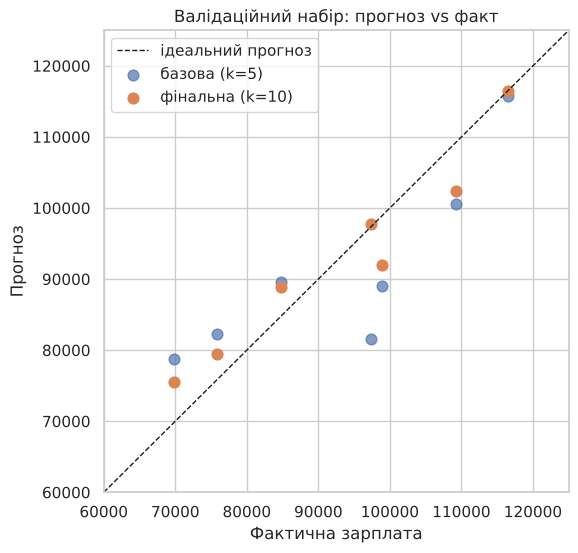

In [24]:
fig, ax = plt.subplots(figsize=(6, 6))
lims = [60000, 125000]
ax.plot(lims, lims, 'k--', lw=1, label='ідеальний прогноз')
ax.scatter(y_valid, y_pred_base, s=60, alpha=0.7, label='базова (k=5)')
ax.scatter(y_valid, y_pred, s=60, label='фінальна (k=10)')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('Фактична зарплата'); ax.set_ylabel('Прогноз')
ax.set_title('Валідаційний набір: прогноз vs факт')
ax.legend()
plt.show()

### 7.3. Аналіз чутливості: MAPE на валідаційному наборі залежно від k

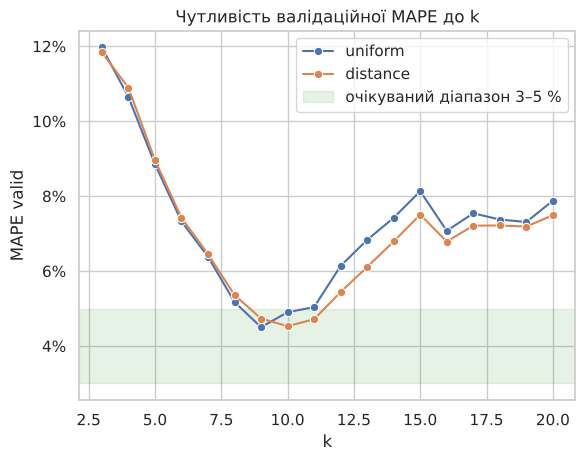

In [25]:
sens = []
for k in range(3, 21):
    for weights in ['uniform', 'distance']:
        m = KNeighborsRegressor(n_neighbors=k, weights=weights).fit(X_train_prep, y_train)
        sens.append((k, weights, mean_absolute_percentage_error(y_valid, m.predict(X_valid_prep))))
sens = pd.DataFrame(sens, columns=['k', 'weights', 'MAPE valid'])

ax = sns.lineplot(data=sens, x='k', y='MAPE valid', hue='weights', marker='o')
ax.axhspan(0.03, 0.05, color='green', alpha=0.1, label='очікуваний діапазон 3–5 %')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title('Чутливість валідаційної MAPE до k')
ax.legend()
plt.show()

## 8. Висновки
1. **EDA.** Набір містить 249 працівників і 8 ознак. Ідентифікатори `Name` і `Phone_Number` виключено; `Date_Of_Birth` перетворено на числову ознаку `Age`. Найсильніше на зарплату впливають `Experience` (r ≈ 0.81), `Role` і `Qualification`; `Cert` і `University` — помірно. Рядки з пропусками (< 3 %) видалено.
2. **Підготовка даних.** Категоріальні ознаки закодовано `OneHotEncoder`, після чого всі ознаки трансформовано й стандартизовано `PowerTransformer` — це важливо для kNN, оскільки метод спирається на відстані. Об'єкти перетворень навчено лише на тренувальних даних.
3. **Модель.** Базова `KNeighborsRegressor` (k = 5) на валідаційному наборі дає MAPE ≈ 8.9 % (R² ≈ 0.68). Після підбору параметрів (крос-валідація `KFold` і `GroupKFold` за профілем) обрано k = 10, `weights='distance'`; фінальна модель досягає **Validation MAPE ≈ 4.5 %**, що відповідає очікуваному діапазону 3–5 % (орієнтир у завданні — 4.54 %). MAE ≈ 4.0 тис., RMSE ≈ 4.8 тис., R² ≈ 0.91 — помилка зменшилась майже вдвічі порівняно з базовою моделлю.
4. **Валідаційний набір** оброблено тими самими навченими `encoder` і `scaler` у тій самій послідовності, що й тренувальний (лише `transform`).
5. **Обмеження.** Валідаційний набір містить лише 7 працівників, і двоє з них мають досвід (6 і 7 років) поза діапазоном тренувальних даних — kNN не може екстраполювати, тому для працівника з 7 роками досвіду прогноз занижений (≈ 6 %). Аналіз чутливості показує, що MAPE на 7 об'єктах сильно змінюється залежно від k, а вибір k (і включення `Age`) у межах плато крос-валідації частково спирався на валідаційний набір (без `Age` валідаційна MAPE при тих самих k була б ≈ 7–8 %). Більш консервативна оцінка точності для нових, раніше не бачених профілів — ≈ 6–7 % (GroupKFold), для «типових» профілів — ≈ 2–3 % (KFold).
6. **Можливі покращення:** зібрати більше даних (особливо з більшим досвідом), спробувати моделі, здатні до екстраполяції (лінійна регресія), або комбінувати kNN з лінійною моделлю.